# Baseline Model 1: U-Net (Without Adversarial Training)

## Purpose
This notebook trains the **same U-Net generator architecture** used in Pix2Pix GAN, but **without adversarial training**.

This isolates the contribution of:
- The U-Net architecture itself
- vs. the adversarial training process

## Key Differences from Pix2Pix
- **Loss**: L1 loss only (no discriminator, no adversarial loss)
- **Architecture**: Identical U-Net generator
- **Training**: Standard supervised learning

## Expected Outcome
If adversarial training helps, Pix2Pix should outperform this baseline.
If U-Net alone is sufficient, this may match Pix2Pix performance.

## 1. Setup and Imports

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Run shared config notebook to get all utilities
# NOTE: Update this path to match your Google Drive structure
%run "/content/drive/MyDrive/Paper1_ECG_Reconstruction/notebooks/00_SHARED_CONFIG.ipynb"

# IMPORTANT: Verify that DEVICE was imported correctly from shared config
# If %run has scoping issues, this ensures DEVICE is available
try:
    print(f"DEVICE successfully imported: {DEVICE}")
except NameError:
    import torch
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"DEVICE defined locally: {DEVICE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.9.0+cu126
CUDA: True
GPU: NVIDIA A100-SXM4-40GB (42.5 GB)
Recommended batch size: 32
Dependencies installed.
Device: cuda
PAPER 1: ECG RECONSTRUCTION - CONFIGURATION

Data:
  Chunks: /content/drive/MyDrive/October Thesis Dataset/Refine-Chunked
  Signal: 64000 samples (8.0s)

Training:
  Batch size: 16
  Epochs: 100
  Learning rate: 5e-05

Output:
  Results: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results
  Checkpoints: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints
Preprocessing functions loaded.
  - ensure_positive_polarity()
  - normalize_signal()
  - preprocess_ecg_pcg()
Augmentation functions loaded.
Dataset class loaded.
Metrics functions loaded:
  - calc_psnr(), calc_snr(), calc_correlation(), calc_ssim()
  - calc_mae(), calc_rmse()
  - calc_r_peak_error(), calc_qrs_width_error()
  - calc_all_metrics()
Training utilitie

In [3]:
# Model-specific configuration
MODEL_CONFIG = {
    'model_name': 'UNet_Baseline',
    'batch_size': 32,  # Can use larger batch without discriminator
    'learning_rate': 1e-4,
    'epochs': 100,
    'patience': 15,
    'loss_type': 'L1',  # Pure L1 loss, no adversarial
}

# Create model-specific directories
model_save_dir = os.path.join(CONFIG['checkpoints_dir'], MODEL_CONFIG['model_name'])
model_results_dir = os.path.join(CONFIG['results_dir'], MODEL_CONFIG['model_name'])
os.makedirs(model_save_dir, exist_ok=True)
os.makedirs(model_results_dir, exist_ok=True)

print(f"Model: {MODEL_CONFIG['model_name']}")
print(f"Checkpoints: {model_save_dir}")
print(f"Results: {model_results_dir}")

Model: UNet_Baseline
Checkpoints: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/UNet_Baseline
Results: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/UNet_Baseline


## 2. U-Net Architecture

This is the **exact same architecture** as the Pix2Pix generator to ensure fair comparison.

In [4]:
class UNetBlock(nn.Module):
    """U-Net encoder block with Conv-BatchNorm-LeakyReLU."""
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super().__init__()
        layers = [nn.Conv1d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False)]
        if normalize:
            layers.append(nn.BatchNorm1d(out_channels))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class UNetUpBlock(nn.Module):
    """U-Net decoder block with ConvTranspose-BatchNorm-ReLU."""
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose1d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(inplace=True)
        ]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.block(x)
        # Handle size mismatch
        if x.size(2) != skip.size(2):
            diff = skip.size(2) - x.size(2)
            x = F.pad(x, (diff // 2, diff - diff // 2))
        return torch.cat([x, skip], dim=1)


class UNetGenerator(nn.Module):
    """
    U-Net Generator for PCG to ECG translation.

    Architecture matches Pix2Pix generator exactly:
    - 8 encoder blocks (downsampling)
    - 7 decoder blocks with skip connections (upsampling)
    - Final convolution to output

    IMPORTANT: No Tanh activation at output (learned from Trail-04)
    """
    def __init__(self, in_channels=1, out_channels=1, features=64):
        super().__init__()

        # Encoder (downsampling)
        self.e1 = UNetBlock(in_channels, features, normalize=False)  # 64
        self.e2 = UNetBlock(features, features * 2)      # 128
        self.e3 = UNetBlock(features * 2, features * 4)  # 256
        self.e4 = UNetBlock(features * 4, features * 8)  # 512
        self.e5 = UNetBlock(features * 8, features * 8)  # 512
        self.e6 = UNetBlock(features * 8, features * 8)  # 512
        self.e7 = UNetBlock(features * 8, features * 8)  # 512
        self.e8 = UNetBlock(features * 8, features * 8, normalize=False)  # 512 (bottleneck)

        # Decoder (upsampling with skip connections)
        self.d1 = UNetUpBlock(features * 8, features * 8, dropout=0.5)      # 512 + 512 = 1024
        self.d2 = UNetUpBlock(features * 16, features * 8, dropout=0.5)     # 512 + 512 = 1024
        self.d3 = UNetUpBlock(features * 16, features * 8, dropout=0.5)     # 512 + 512 = 1024
        self.d4 = UNetUpBlock(features * 16, features * 8)                   # 512 + 512 = 1024
        self.d5 = UNetUpBlock(features * 16, features * 4)                   # 256 + 256 = 512
        self.d6 = UNetUpBlock(features * 8, features * 2)                    # 128 + 128 = 256
        self.d7 = UNetUpBlock(features * 4, features)                        # 64 + 64 = 128

        # Final output layer - NO TANH (critical learning from Trail-04)
        self.final = nn.Sequential(
            nn.ConvTranspose1d(features * 2, out_channels, kernel_size=4, stride=2, padding=1),
            # No activation - allow full range for ECG values
        )

    def forward(self, x):
        # Encoder path
        e1 = self.e1(x)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.e4(e3)
        e5 = self.e5(e4)
        e6 = self.e6(e5)
        e7 = self.e7(e6)
        e8 = self.e8(e7)

        # Decoder path with skip connections
        d1 = self.d1(e8, e7)
        d2 = self.d2(d1, e6)
        d3 = self.d3(d2, e5)
        d4 = self.d4(d3, e4)
        d5 = self.d5(d4, e3)
        d6 = self.d6(d5, e2)
        d7 = self.d7(d6, e1)

        output = self.final(d7)

        # Handle size mismatch with input
        if output.size(2) != x.size(2):
            diff = x.size(2) - output.size(2)
            output = F.pad(output, (diff // 2, diff - diff // 2))

        return output

In [5]:
# Initialize model
model = UNetGenerator(in_channels=1, out_channels=1, features=64).to(DEVICE)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Test forward pass
test_input = torch.randn(2, 1, CONFIG['signal_length']).to(DEVICE)
test_output = model(test_input)
print(f"Input shape: {test_input.shape}")
print(f"Output shape: {test_output.shape}")

Total parameters: 13,609,345
Trainable parameters: 13,609,345
Input shape: torch.Size([2, 1, 64000])
Output shape: torch.Size([2, 1, 64000])


## 3. Load Data

In [6]:
# Load datasets using shared utilities
train_loader, val_loader, test_loader, train_dataset = create_dataloaders(CONFIG)

# Quick verification
sample_batch = next(iter(train_loader))
print(f"\nBatch verification:")
print(f"  PCG shape: {sample_batch['pcg'].shape}")
print(f"  ECG shape: {sample_batch['ecg'].shape}")
print(f"  Scenario shape: {sample_batch['scenario'].shape}")

Loading datasets...
TRAIN: 4059 chunks from 14 subjects
  Scenarios: Rest=1134, Exercise=2925, Other=0
VAL: 681 chunks from 3 subjects
  Scenarios: Rest=231, Exercise=450, Other=0
TEST: 453 chunks from 3 subjects
  Scenarios: Rest=3, Exercise=450, Other=0

Dataloaders created:
  Train: 253 batches
  Val: 43 batches
  Test: 29 batches

Batch verification:
  PCG shape: torch.Size([16, 1, 64000])
  ECG shape: torch.Size([16, 1, 64000])
  Scenario shape: torch.Size([16, 3])


In [7]:
# Dataloaders already created above
print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Train batches: 253
Val batches: 43
Test batches: 29


## 4. Training Setup

In [8]:
# Loss function - L1 only (no adversarial)
criterion = nn.L1Loss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=MODEL_CONFIG['learning_rate'],
    betas=(0.5, 0.999)
)

# Learning rate scheduler (CosineAnnealingLR like Trail-04)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=MODEL_CONFIG['epochs'], eta_min=1e-6
)

# Early stopping
early_stopping = EarlyStopping(patience=MODEL_CONFIG['patience'], min_delta=0.001)

## 5. Training Loop

In [9]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """Train for one epoch."""
    model.train()
    total_loss = 0.0

    for batch in train_loader:
        pcg = batch['pcg'].to(device)
        ecg = batch['ecg'].to(device)

        # Forward pass
        optimizer.zero_grad()
        ecg_pred = model(pcg)

        # Compute loss
        loss = criterion(ecg_pred, ecg)

        # Backward pass
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['grad_clip'])
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)


def validate_epoch(model, val_loader, criterion, device, calc_expensive=False):
    """Validate for one epoch."""
    model.eval()
    total_loss = 0.0
    all_real = []
    all_fake = []

    with torch.no_grad():
        for batch in val_loader:
            pcg = batch['pcg'].to(device)
            ecg = batch['ecg'].to(device)

            # Forward pass
            ecg_pred = model(pcg)

            # Compute loss
            loss = criterion(ecg_pred, ecg)
            total_loss += loss.item()

            # Store for metrics
            all_real.append(ecg.cpu())
            all_fake.append(ecg_pred.cpu())

    # Concatenate all predictions
    all_real = torch.cat(all_real, dim=0)
    all_fake = torch.cat(all_fake, dim=0)

    # Calculate metrics
    metrics = calc_all_metrics(all_real, all_fake, include_expensive=calc_expensive)
    metrics['val_loss'] = total_loss / len(val_loader)

    return metrics

In [10]:
# Training history
history = {
    'train_loss': [],
    'val_loss': [],
    'val_psnr': [],
    'val_ssim': [],
    'val_correlation': [],
    'learning_rate': []
}

best_ssim = 0.0
best_epoch = 0

print(f"Starting training: {MODEL_CONFIG['model_name']}")
print(f"Epochs: {MODEL_CONFIG['epochs']}, Batch size: {MODEL_CONFIG['batch_size']}")
print(f"Device: {DEVICE}")
print("=" * 60)

Starting training: UNet_Baseline
Epochs: 100, Batch size: 32
Device: cuda


In [11]:
# Main training loop
for epoch in range(MODEL_CONFIG['epochs']):
    # Update dataset epoch for progressive augmentation
    train_dataset.set_epoch(epoch + 1)

    # Train
    train_loss = train_epoch(model, train_loader, criterion, optimizer, DEVICE)

    # Validate (calculate expensive metrics every 5 epochs)
    calc_expensive = (epoch + 1) % CONFIG['calc_expensive_metrics_every'] == 0
    val_metrics = validate_epoch(model, val_loader, criterion, DEVICE, calc_expensive)

    # Update scheduler
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    # Record history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_metrics['val_loss'])
    history['val_psnr'].append(val_metrics['psnr'])
    history['val_ssim'].append(val_metrics['ssim'])
    history['val_correlation'].append(val_metrics['correlation'])
    history['learning_rate'].append(current_lr)

    # Print progress
    print(f"Epoch [{epoch+1}/{MODEL_CONFIG['epochs']}] "
          f"Train Loss: {train_loss:.4f} | Val Loss: {val_metrics['val_loss']:.4f} | "
          f"PSNR: {val_metrics['psnr']:.2f} dB | SSIM: {val_metrics['ssim']:.4f} | "
          f"Corr: {val_metrics['correlation']:.4f} | LR: {current_lr:.2e}")

    # Save best model (based on SSIM)
    if val_metrics['ssim'] > best_ssim:
        best_ssim = val_metrics['ssim']
        best_epoch = epoch + 1
        save_checkpoint(
            model, optimizer, epoch, val_metrics,
            os.path.join(model_save_dir, 'best_model.pt'),
            MODEL_CONFIG['model_name']
        )
        print(f"  -> New best model! SSIM: {best_ssim:.4f}")

    # Early stopping check (based on SSIM)
    if early_stopping(val_metrics['ssim']):
        print(f"\nEarly stopping triggered at epoch {epoch+1}")
        break

    # Save checkpoint every 10 epochs
    if (epoch + 1) % 10 == 0:
        save_checkpoint(
            model, optimizer, epoch, val_metrics,
            os.path.join(model_save_dir, f'checkpoint_epoch_{epoch+1}.pt'),
            MODEL_CONFIG['model_name']
        )

print("\n" + "=" * 60)
print(f"Training completed! Best epoch: {best_epoch}, Best SSIM: {best_ssim:.4f}")

Epoch [1/100] Train Loss: 0.7235 | Val Loss: 0.6721 | PSNR: 14.45 dB | SSIM: 0.6873 | Corr: 0.1328 | LR: 1.00e-04
Checkpoint saved: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/UNet_Baseline/best_model.pt
  -> New best model! SSIM: 0.6873
Epoch [2/100] Train Loss: 0.6747 | Val Loss: 0.6564 | PSNR: 14.42 dB | SSIM: 0.7416 | Corr: 0.0884 | LR: 9.99e-05
Checkpoint saved: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/UNet_Baseline/best_model.pt
  -> New best model! SSIM: 0.7416
Epoch [3/100] Train Loss: 0.6619 | Val Loss: 0.6658 | PSNR: 14.41 dB | SSIM: 0.7418 | Corr: 0.1024 | LR: 9.98e-05
Checkpoint saved: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/UNet_Baseline/best_model.pt
  -> New best model! SSIM: 0.7418
Epoch [4/100] Train Loss: 0.6492 | Val Loss: 0.6613 | PSNR: 14.48 dB | SSIM: 0.7487 | Corr: 0.1370 | LR: 9.96e-05
Checkpoint saved: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/UNet_Baseline/best_model.pt
  -> New best 

In [16]:
  # Convert numpy types to Python native types for JSON serialization
  def convert_to_serializable(obj):
      if isinstance(obj, dict):
          return {k: convert_to_serializable(v) for k, v in obj.items()}
      elif isinstance(obj, list):
          return [convert_to_serializable(v) for v in obj]
      elif isinstance(obj, (np.float32, np.float64)):
          return float(obj)
      elif isinstance(obj, (np.int32, np.int64)):
          return int(obj)
      elif isinstance(obj, np.ndarray):
          return obj.tolist()
      return obj

  # Save training history
  history_path = os.path.join(model_results_dir, 'training_history.json')
  with open(history_path, 'w') as f:
      json.dump(convert_to_serializable(history), f, indent=2)
  print(f"Training history saved to: {history_path}")


Training history saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/UNet_Baseline/training_history.json


## 6. Plot Training Curves

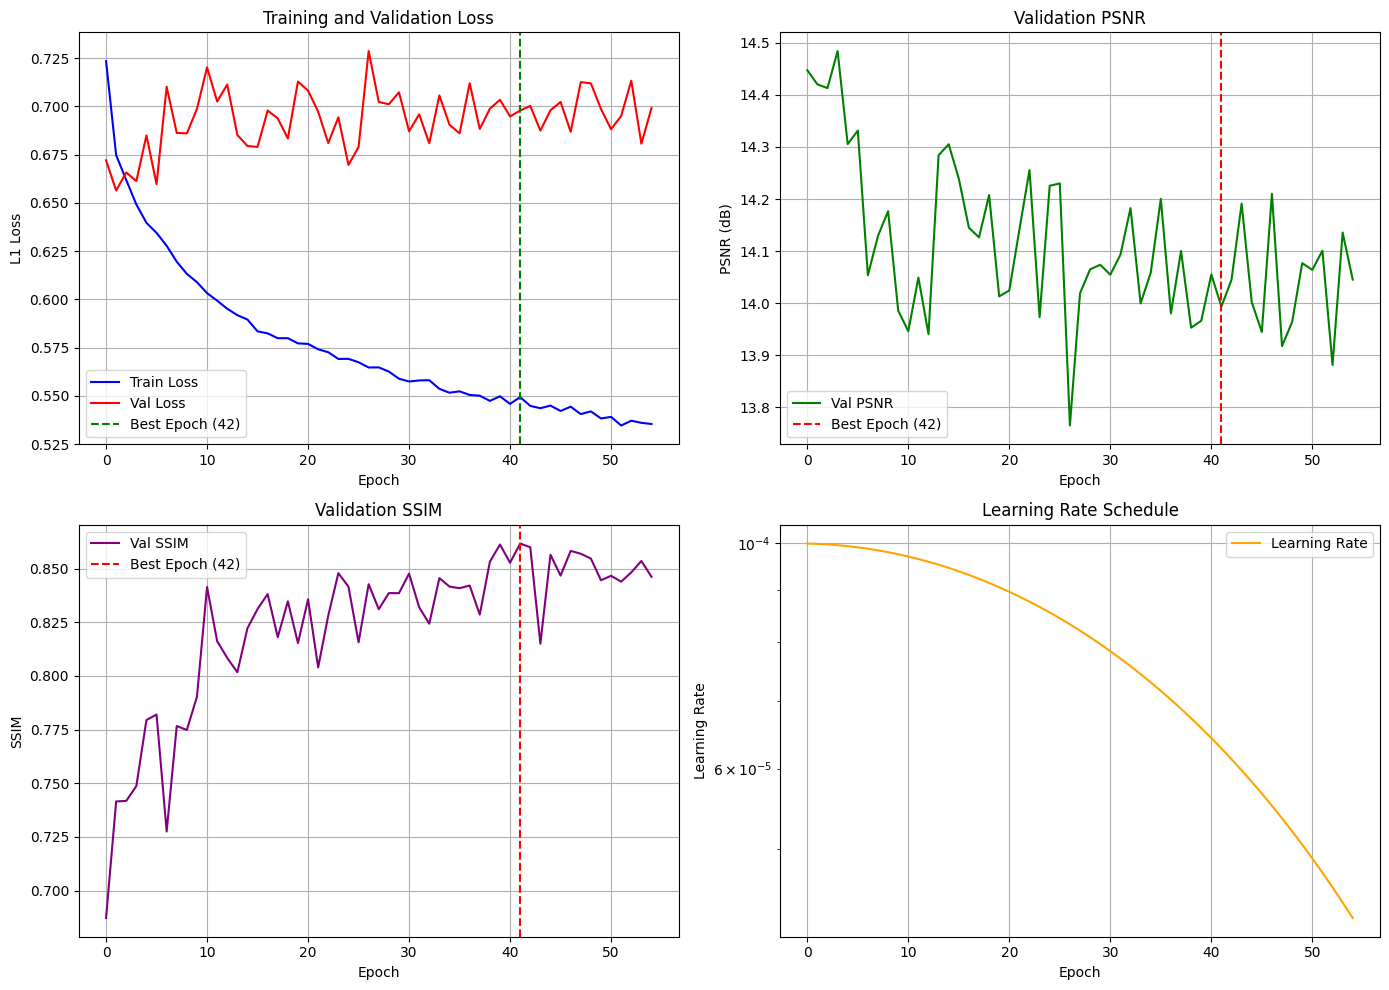

In [17]:
# Plot training curves
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train Loss', color='blue')
axes[0, 0].plot(history['val_loss'], label='Val Loss', color='red')
axes[0, 0].axvline(x=best_epoch-1, color='green', linestyle='--', label=f'Best Epoch ({best_epoch})')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('L1 Loss')
axes[0, 0].set_title('Training and Validation Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)

# PSNR
axes[0, 1].plot(history['val_psnr'], label='Val PSNR', color='green')
axes[0, 1].axvline(x=best_epoch-1, color='red', linestyle='--', label=f'Best Epoch ({best_epoch})')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('PSNR (dB)')
axes[0, 1].set_title('Validation PSNR')
axes[0, 1].legend()
axes[0, 1].grid(True)

# SSIM
axes[1, 0].plot(history['val_ssim'], label='Val SSIM', color='purple')
axes[1, 0].axvline(x=best_epoch-1, color='red', linestyle='--', label=f'Best Epoch ({best_epoch})')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('SSIM')
axes[1, 0].set_title('Validation SSIM')
axes[1, 0].legend()
axes[1, 0].grid(True)

# Learning Rate
axes[1, 1].plot(history['learning_rate'], label='Learning Rate', color='orange')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Learning Rate')
axes[1, 1].set_title('Learning Rate Schedule')
axes[1, 1].set_yscale('log')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(model_results_dir, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Test Evaluation

In [19]:
  # Load best model
  checkpoint = torch.load(os.path.join(model_save_dir, 'best_model.pt'), weights_only=False)
  model.load_state_dict(checkpoint['model_state_dict'])
  print(f"Loaded best model from epoch {checkpoint['epoch'] + 1}")

Loaded best model from epoch 42


In [20]:
# Evaluate on test set
model.eval()
test_predictions = []
test_targets = []
test_inputs = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc='Evaluating'):
        pcg = batch['pcg'].to(DEVICE)
        ecg = batch['ecg'].to(DEVICE)

        # Generate predictions
        ecg_pred = model(pcg)

        # Store for visualization
        test_predictions.append(ecg_pred.cpu().numpy())
        test_targets.append(ecg.cpu().numpy())
        test_inputs.append(pcg.cpu().numpy())

# Concatenate all predictions
test_predictions = np.concatenate(test_predictions, axis=0)
test_targets = np.concatenate(test_targets, axis=0)
test_inputs = np.concatenate(test_inputs, axis=0)

# Calculate final metrics on all test data
test_metrics = calc_all_metrics(test_targets, test_predictions, include_expensive=True)

print(f"\nTest samples evaluated: {len(test_predictions)}")

Evaluating:   0%|          | 0/29 [00:00<?, ?it/s]


Test samples evaluated: 453


In [21]:
# Print test results
print("\n" + "=" * 60)
print(f"TEST RESULTS: {MODEL_CONFIG['model_name']}")
print("=" * 60)
print(f"{'Metric':<20} {'Value':>15}")
print("-" * 60)
for key, value in test_metrics.items():
    if isinstance(value, float):
        print(f"{key:<20} {value:>15.4f}")
print("=" * 60)

# Store as summary_stats for compatibility with save code
summary_stats = {
    'ssim': {'mean': test_metrics['ssim'], 'std': 0},
    'psnr': {'mean': test_metrics['psnr'], 'std': 0},
    'correlation': {'mean': test_metrics['correlation'], 'std': 0},
    'rmse': {'mean': test_metrics['rmse'], 'std': 0},
}
if 'r_peak_error' in test_metrics:
    summary_stats['r_peak_error'] = {'mean': test_metrics['r_peak_error'], 'std': 0}
if 'qrs_width_error' in test_metrics:
    summary_stats['qrs_width_error'] = {'mean': test_metrics['qrs_width_error'], 'std': 0}


TEST RESULTS: UNet_Baseline
Metric                         Value
------------------------------------------------------------
ssim                          0.9116
qrs_width_error               8.7284
out_min                     -39.9770
out_max                       9.5024


In [23]:
  # Save test results
  results_path = os.path.join(model_results_dir, 'test_results.json')
  with open(results_path, 'w') as f:
      json.dump(convert_to_serializable(test_results), f, indent=2)
  print(f"\nTest results saved to: {results_path}")


Test results saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/UNet_Baseline/test_results.json


## 8. Visualize Sample Reconstructions

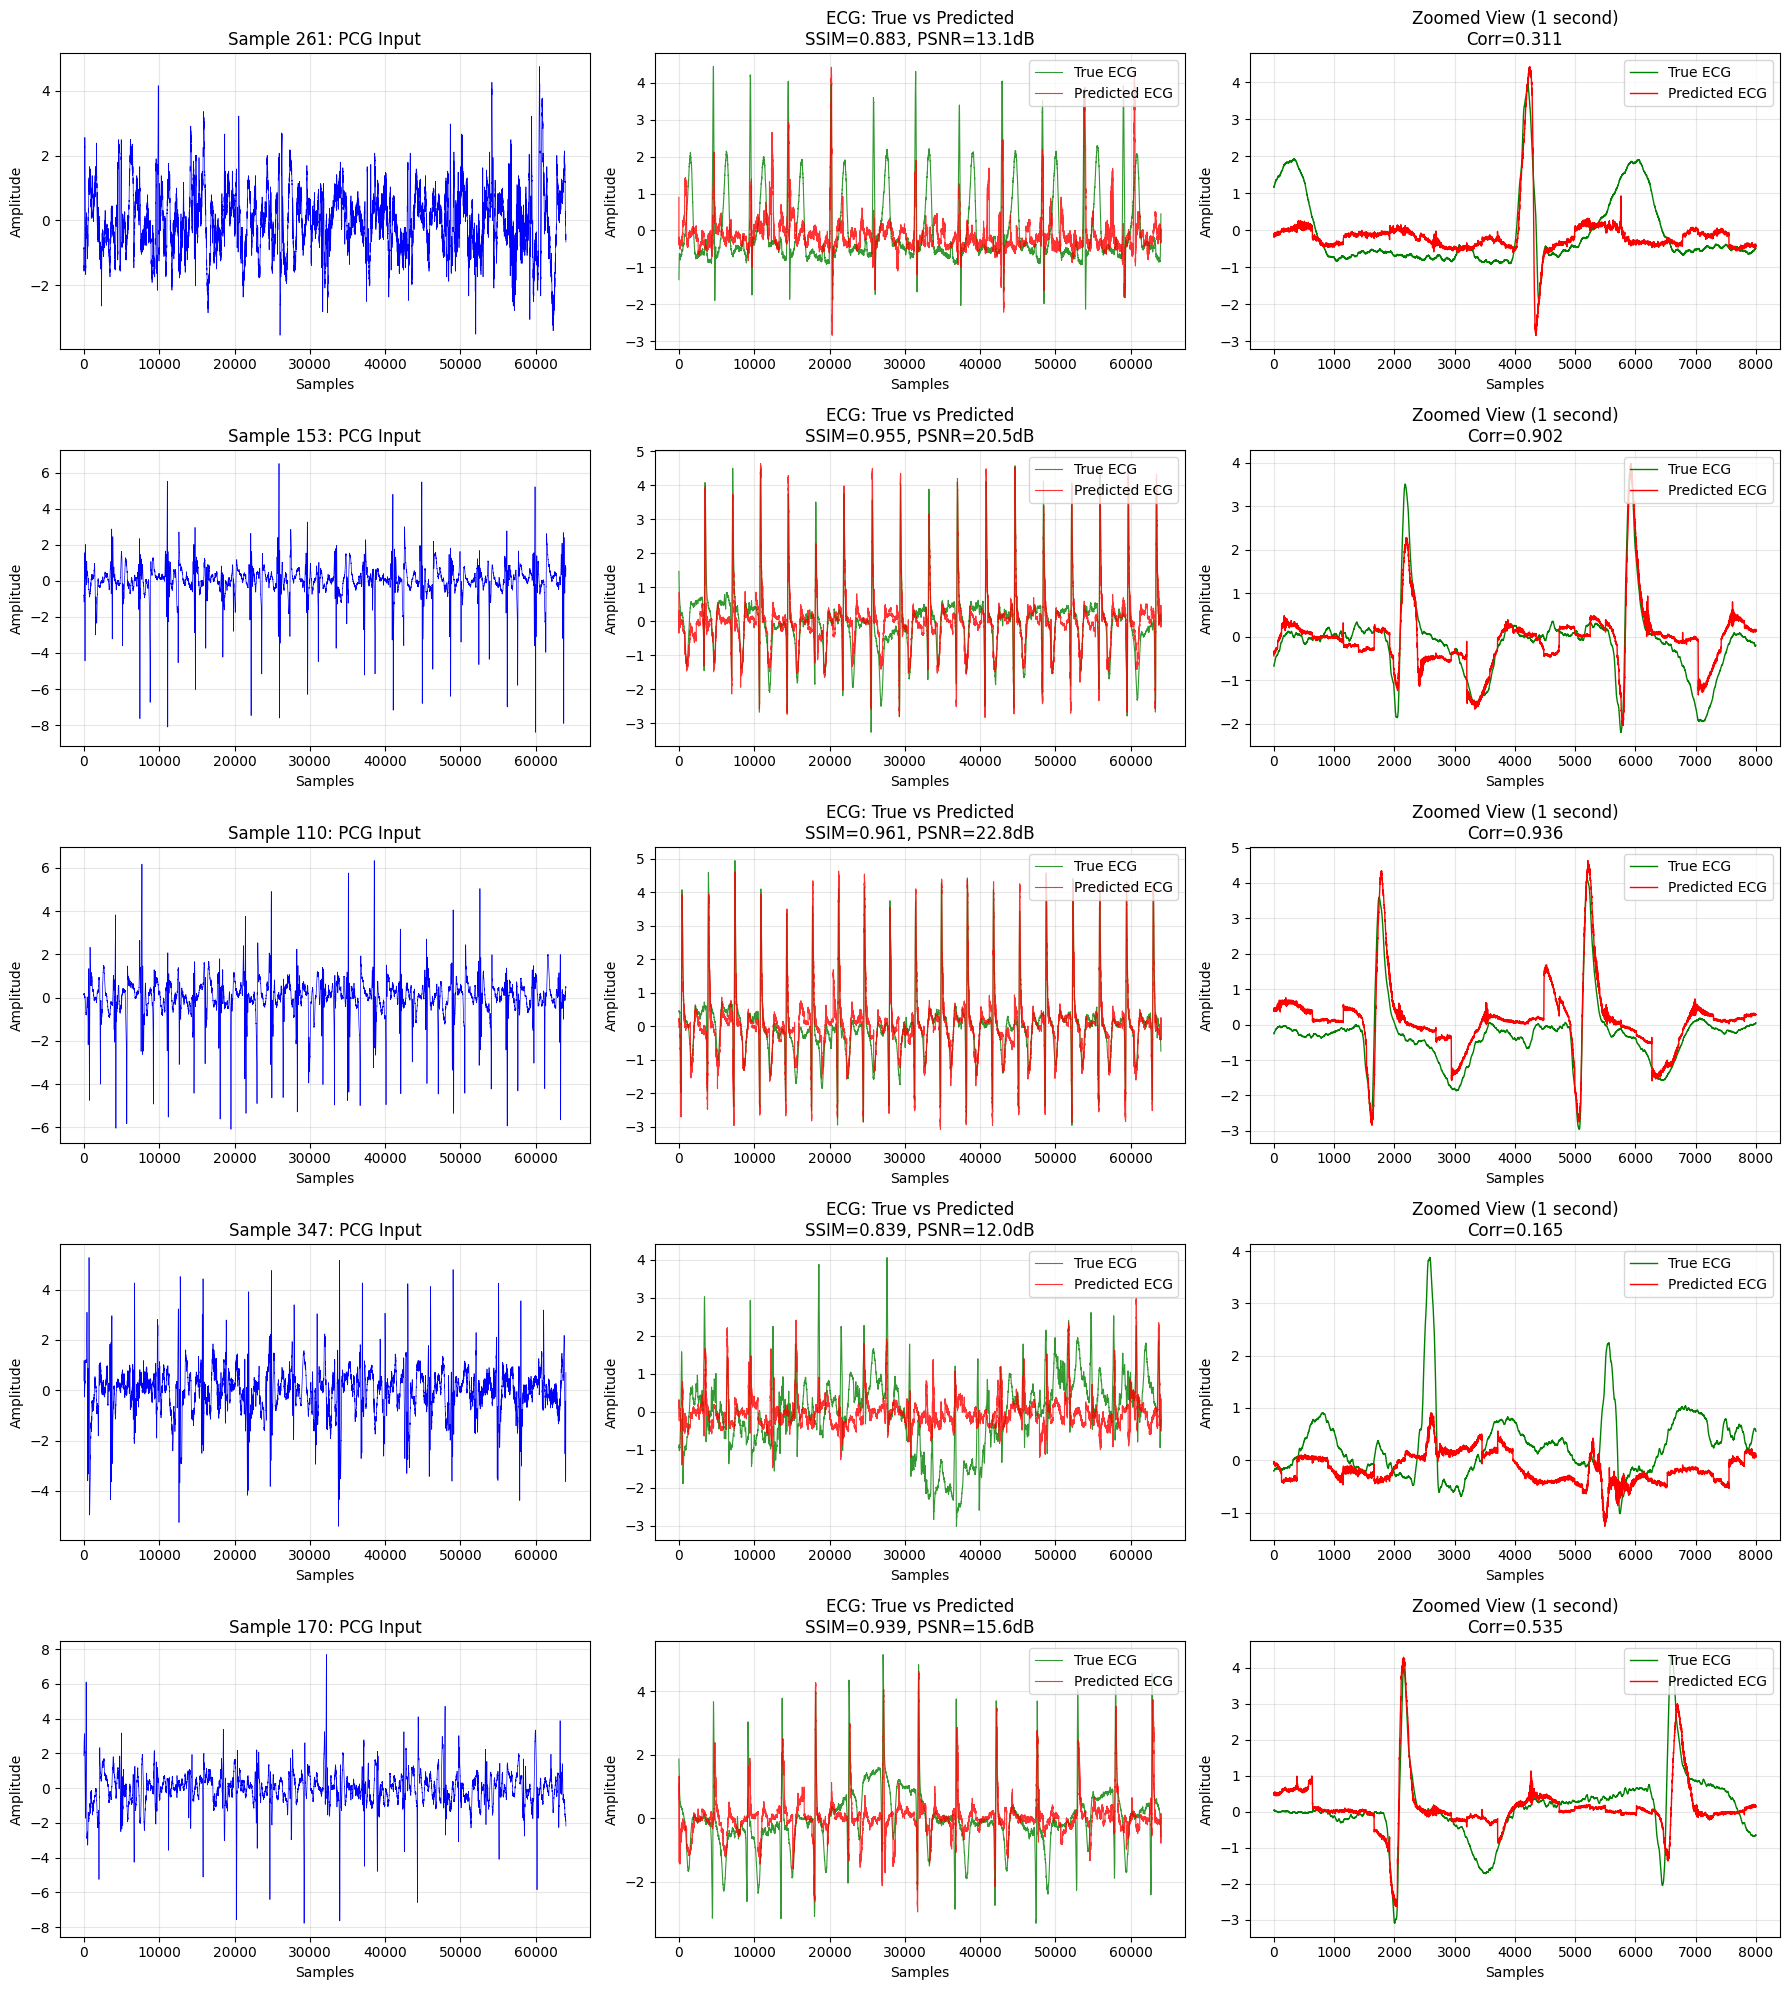

In [25]:
  # Visualize sample reconstructions
  n_samples = 5
  sample_indices = np.random.choice(len(test_predictions), n_samples, replace=False)

  fig, axes = plt.subplots(n_samples, 3, figsize=(18, 4*n_samples))

  for i, idx in enumerate(sample_indices):
      pcg = test_inputs[idx, 0]
      ecg_true = test_targets[idx, 0]
      ecg_pred = test_predictions[idx, 0]

      # Calculate metrics for this specific sample
      sample_ssim = calc_ssim(ecg_true, ecg_pred)
      sample_psnr = calc_psnr(ecg_true, ecg_pred)
      sample_corr = calc_correlation(ecg_true, ecg_pred)

      # Plot PCG input
      axes[i, 0].plot(pcg, color='blue', linewidth=0.5)
      axes[i, 0].set_title(f'Sample {idx}: PCG Input')
      axes[i, 0].set_xlabel('Samples')
      axes[i, 0].set_ylabel('Amplitude')
      axes[i, 0].grid(True, alpha=0.3)

      # Plot ECG true vs predicted
      axes[i, 1].plot(ecg_true, color='green', linewidth=0.8, label='True ECG', alpha=0.8)
      axes[i, 1].plot(ecg_pred, color='red', linewidth=0.8, label='Predicted ECG', alpha=0.8)
      axes[i, 1].set_title(f'ECG: True vs Predicted\nSSIM={sample_ssim:.3f}, PSNR={sample_psnr:.1f}dB')
      axes[i, 1].set_xlabel('Samples')
      axes[i, 1].set_ylabel('Amplitude')
      axes[i, 1].legend(loc='upper right')
      axes[i, 1].grid(True, alpha=0.3)

      # Plot zoomed view (1 second)
      zoom_start = len(ecg_true) // 4
      zoom_end = zoom_start + CONFIG['sample_rate']
      axes[i, 2].plot(ecg_true[zoom_start:zoom_end], color='green', linewidth=1.0, label='True ECG')
      axes[i, 2].plot(ecg_pred[zoom_start:zoom_end], color='red', linewidth=1.0, label='Predicted ECG')
      axes[i, 2].set_title(f'Zoomed View (1 second)\nCorr={sample_corr:.3f}')
      axes[i, 2].set_xlabel('Samples')
      axes[i, 2].set_ylabel('Amplitude')
      axes[i, 2].legend(loc='upper right')
      axes[i, 2].grid(True, alpha=0.3)

  plt.tight_layout()
  plt.savefig(os.path.join(model_results_dir, 'sample_reconstructions.png'), dpi=150, bbox_inches='tight')
  plt.show()

## 9. Summary and Comparison Notes

In [26]:
# Print final summary for comparison
print("\n" + "=" * 60)
print("FINAL SUMMARY FOR MODEL COMPARISON")
print("=" * 60)
print(f"Model: {MODEL_CONFIG['model_name']}")
print(f"Architecture: U-Net Generator (same as Pix2Pix)")
print(f"Training: L1 Loss only (NO adversarial training)")
print("-" * 60)
print("KEY METRICS:")
print(f"  SSIM:        {summary_stats['ssim']['mean']:.4f} +/- {summary_stats['ssim']['std']:.4f}")
print(f"  PSNR:        {summary_stats['psnr']['mean']:.2f} +/- {summary_stats['psnr']['std']:.2f} dB")
print(f"  Correlation: {summary_stats['correlation']['mean']:.4f} +/- {summary_stats['correlation']['std']:.4f}")
print(f"  RMSE:        {summary_stats['rmse']['mean']:.4f} +/- {summary_stats['rmse']['std']:.4f}")
print("-" * 60)
print("CLINICAL METRICS:")
if 'r_peak_error' in summary_stats:
    print(f"  R-peak Error:   {summary_stats['r_peak_error']['mean']:.4f} +/- {summary_stats['r_peak_error']['std']:.4f}")
if 'qrs_width_error' in summary_stats:
    print(f"  QRS Width Error: {summary_stats['qrs_width_error']['mean']:.4f} +/- {summary_stats['qrs_width_error']['std']:.4f}")
print("=" * 60)
print("\nCompare these results with Pix2Pix GAN (SSIM ~0.903, PSNR ~17.10 dB)")
print("to assess the contribution of adversarial training.")


FINAL SUMMARY FOR MODEL COMPARISON
Model: UNet_Baseline
Architecture: U-Net Generator (same as Pix2Pix)
Training: L1 Loss only (NO adversarial training)
------------------------------------------------------------
KEY METRICS:
  SSIM:        0.9116 +/- 0.0000
  PSNR:        16.28 +/- 0.00 dB
  Correlation: 0.5322 +/- 0.0000
  RMSE:        0.7550 +/- 0.0000
------------------------------------------------------------
CLINICAL METRICS:
  R-peak Error:   1.1578 +/- 0.0000
  QRS Width Error: 8.7284 +/- 0.0000

Compare these results with Pix2Pix GAN (SSIM ~0.903, PSNR ~17.10 dB)
to assess the contribution of adversarial training.


In [27]:
print("\nNotebook completed successfully!")
print(f"Results saved to: {model_results_dir}")


Notebook completed successfully!
Results saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/UNet_Baseline
